In [8]:
import pandas as pd
import requests
import zipfile
from io import BytesIO

# Baixar o ZIP diretamente do GitHub
url = "https://raw.githubusercontent.com/andretorquato443/lab3---cg--andr-/main/archive%20(1).zip"

response = requests.get(url)
response.raise_for_status()

# Abrir o ZIP sem precisar salvá-lo no computador
arquivo_zip = zipfile.ZipFile(BytesIO(response.content))

# Encontrar o arquivo CSV dentro do ZIP
csv_files = [f for f in arquivo_zip.namelist() if f.lower().endswith(".csv")]

if not csv_files:
    raise ValueError("Nenhum arquivo CSV foi encontrado dentro do ZIP.")

# Carregar o CSV
with arquivo_zip.open(csv_files[0]) as arquivo:
    df = pd.read_csv(arquivo)

print("Dataset carregado com sucesso!")
print("Dimensões:", df.shape)
display(df.head())

Dataset carregado com sucesso!
Dimensões: (4464, 13)


,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


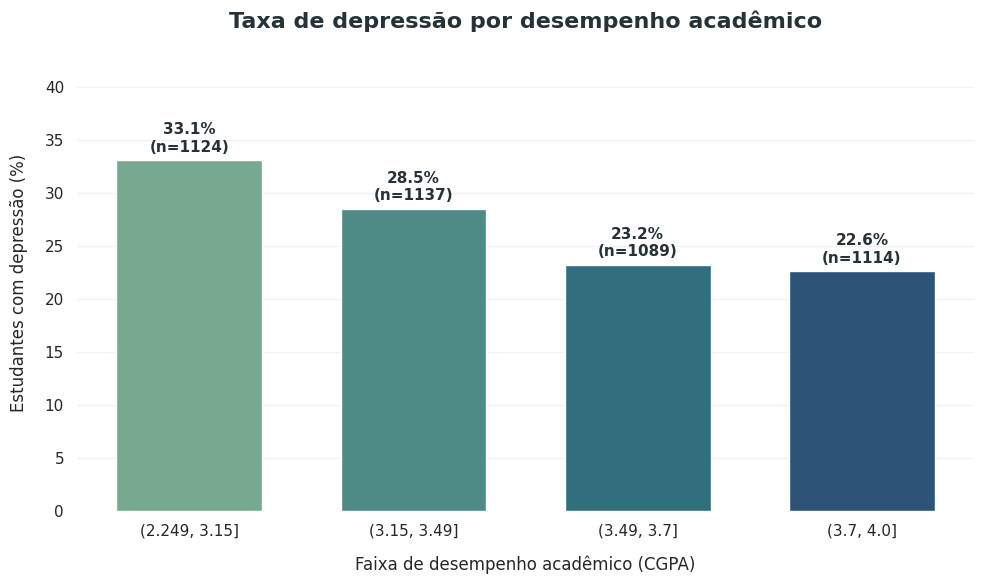

,CGPA_group,total,depression_yes,percentage
0,"(2.249, 3.15]",1124,372,33.096085
1,"(3.15, 3.49]",1137,324,28.496042
2,"(3.49, 3.7]",1089,253,23.232323
3,"(3.7, 4.0]",1114,252,22.621185


In [9]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

# 1. Dividir os estudantes em quatro grupos
df["CGPA_group"] = pd.qcut(
    df["CGPA"],
    q=4,
    duplicates="drop"
)

# 2. Calcular quantidade e percentual
summary = df.groupby(
    "CGPA_group",
    observed=True
).agg(
    total=("Depression", "count"),
    depression_yes=("Depression", lambda x: (x == "Yes").sum())
).reset_index()

summary["percentage"] = (
    summary["depression_yes"] / summary["total"] * 100
)

# 3. Criar gráfico
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=summary,
    x="CGPA_group",
    y="percentage",
    palette=sns.color_palette("crest", n_colors=len(summary)),
    hue="CGPA_group",
    legend=False,
    width=0.65,
    ax=ax
)

# 4. Adicionar percentuais e quantidades
for i, row in summary.iterrows():
    ax.text(
        i,
        row["percentage"] + 0.8,
        f'{row["percentage"]:.1f}%\n(n={row["total"]})',
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#263238"
    )

# 5. Personalização
ax.set_title(
    "Taxa de depressão por desempenho acadêmico",
    fontsize=16,
    fontweight="bold",
    color="#263238",
    pad=20
)

ax.set_xlabel("Faixa de desempenho acadêmico (CGPA)", fontsize=12, labelpad=12)
ax.set_ylabel("Estudantes com depressão (%)", fontsize=12, labelpad=12)

ax.set_ylim(0, 43)
ax.set_yticks(range(0, 41, 5))

ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig("desempenho_academico.png", dpi=300, bbox_inches="tight")
plt.show()

display(summary)


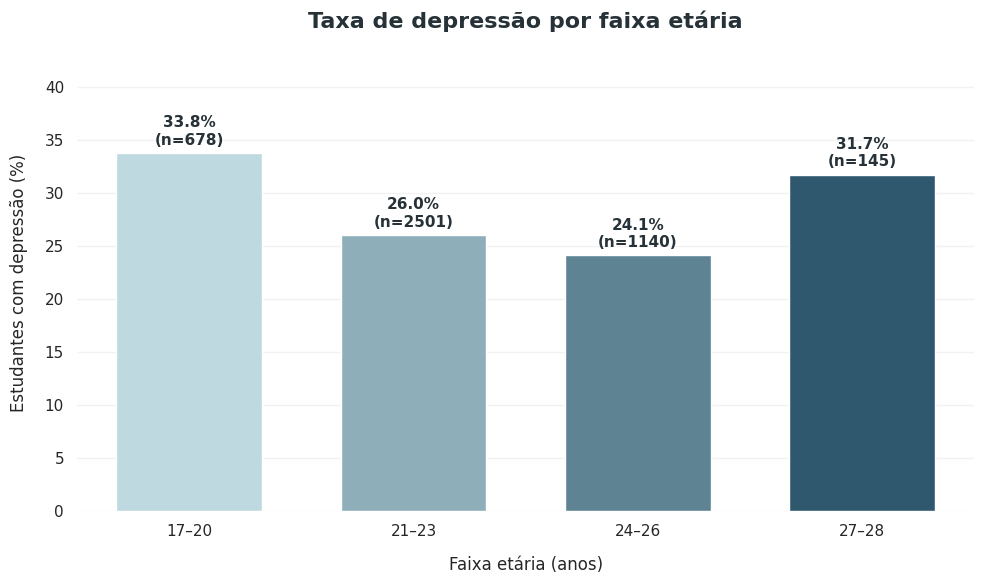

,Age_group,total,depression_yes,percentage
0,17–20,678,229,33.775811
1,21–23,2501,651,26.029588
2,24–26,1140,275,24.122807
3,27–28,145,46,31.724138


In [10]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuração visual
sns.set_theme(style="whitegrid")
plt.rcParams["font.family"] = "DejaVu Sans"

# 1. Criar faixas etárias
df["Age_group"] = pd.cut(
    df["Age"],
    bins=[16, 20, 23, 26, 28],
    labels=["17–20", "21–23", "24–26", "27–28"]
)

# 2. Calcular quantidade e percentual
age_summary = df.groupby(
    "Age_group",
    observed=True
).agg(
    total=("Depression", "count"),
    depression_yes=("Depression", lambda x: (x == "Yes").sum())
).reset_index()

age_summary["percentage"] = (
    age_summary["depression_yes"] / age_summary["total"] * 100
)

# 3. Criar gráfico
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=age_summary,
    x="Age_group",
    y="percentage",
    palette=sns.color_palette("blend:#B8DCE5,#245B78", n_colors=len(age_summary)),
    hue="Age_group",
    legend=False,
    width=0.65,
    ax=ax
)

# 4. Adicionar percentuais e quantidades
for i, row in age_summary.iterrows():
    ax.text(
        i,
        row["percentage"] + 0.8,
        f'{row["percentage"]:.1f}%\n(n={row["total"]})',
        ha="center",
        fontsize=11,
        fontweight="bold",
        color="#263238"
    )

# 5. Personalização
ax.set_title(
    "Taxa de depressão por faixa etária",
    fontsize=16,
    fontweight="bold",
    color="#263238",
    pad=20
)

ax.set_xlabel("Faixa etária (anos)", fontsize=12, labelpad=12)
ax.set_ylabel("Estudantes com depressão (%)", fontsize=12, labelpad=12)

ax.set_ylim(0, 43)
ax.set_yticks(range(0, 41, 5))

ax.grid(axis="y", alpha=0.25)
ax.grid(axis="x", visible=False)

sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.savefig("depressao_por_idade.png", dpi=300, bbox_inches="tight")
plt.show()

display(age_summary)
